In [3]:
import pandas as pd 

In [19]:
df = pd.read_csv("datasets/bank_migration_dataset.csv")

In [20]:
df

,sample_id,forecast_year,target_year,origin_year,horizon_years,elapsed_years,transect_id,side,reach,along_m,...,abs_curvature_1_m,sinuosity,is_left_bank,feature_cutoff_year,last_rate_missing,last2_missing,last3_missing,width_missing,curvature_missing,sinuosity_missing
0,T001_L_1989_1990,1990,1990,1989,1,0.999316,1,L,north,0.0,...,NaN,NaN,1,1989,1,1,1,1,1,1
1,T001_R_1989_1990,1990,1990,1989,1,0.999316,1,R,north,0.0,...,NaN,NaN,0,1989,1,1,1,1,1,1
2,T002_L_1989_1990,1990,1990,1989,1,0.999316,2,L,north,360.0,...,NaN,NaN,1,1989,1,1,1,1,1,1
3,T002_R_1989_1990,1990,1990,1989,1,0.999316,2,R,north,360.0,...,NaN,NaN,0,1989,1,1,1,1,1,1
4,T003_L_1989_1990,1990,1990,1989,1,0.999316,3,L,north,720.0,...,NaN,NaN,1,1989,1,1,1,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13945,T073_R_2022_2023,2023,2023,2022,1,0.999316,73,R,south,25920.0,...,0.000027,1.011294,0,2022,0,0,0,0,0,0
13946,T074_L_2022_2023,2023,2023,2022,1,0.999316,74,L,south,26280.0,...,0.000012,1.076480,1,2022,0,0,0,0,0,0
13947,T074_R_2022_2023,2023,2023,2022,1,0.999316,74,R,south,26280.0,...,0.000001,1.011478,0,2022,0,0,0,0,0,0
13948,T075_L_2022_2023,2023,2023,2022,1,0.999316,75,L,south,26640.0,...,0.000019,1.075387,1,2022,0,0,0,0,0,0


In [21]:
import seaborn as sns

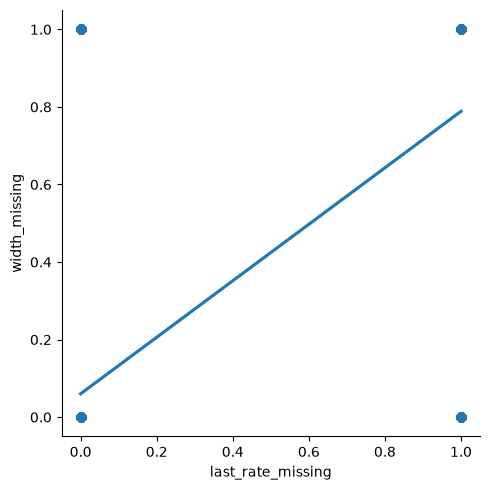

In [31]:
sns.lmplot(x="last_rate_missing" , y="width_missing" , data = df, fit_reg = True , ci = None )

In [33]:
df.corr(numeric_only=True)["target_displacement_m"].round(5)

forecast_year              -0.03792
target_year                -0.03792
origin_year                -0.03677
horizon_years              -0.01241
elapsed_years              -0.01232
transect_id                -0.01755
along_m                    -0.01755
origin_bank_x              -0.01286
origin_bank_y               0.01984
normal_x                   -0.02095
normal_y                    0.01672
outward_sign                0.01732
target_displacement_m       1.00000
target_rate_m_per_yr        0.90301
target_bank_x              -0.01040
target_bank_y               0.02288
usable_for_training        -0.01915
last_rate_m_per_yr         -0.27163
last2_mean_rate_m_per_yr   -0.20818
last3_mean_rate_m_per_yr   -0.15244
acceleration_m_per_yr2     -0.13727
last_displacement_m        -0.27590
last_interval_years         0.01569
last_interval_good         -0.04427
width_m                    -0.24461
width_change_last_m        -0.22941
abs_curvature_1_m          -0.08717
sinuosity                  -

In [26]:
import matplotlib.pyplot as plt

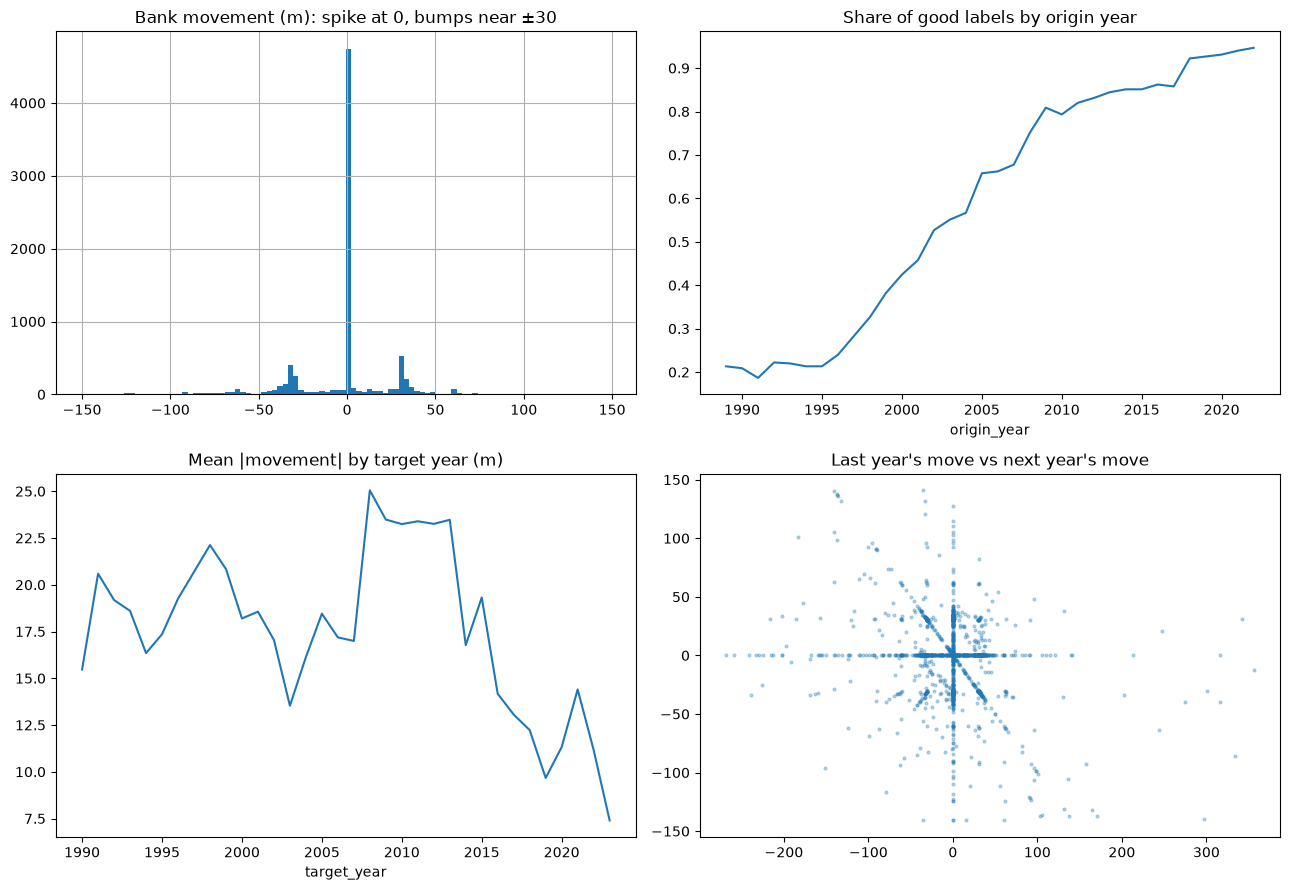

In [27]:
u = df[df.usable_for_training]
h1 = u[(u.horizon_years == 1) & u.last_displacement_m.notna()]
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
u.target_displacement_m.hist(bins=100, ax=ax[0,0]); ax[0,0].set_title("Bank movement (m): spike at 0, bumps near ±30")
(df.label_quality == "good").groupby(df.origin_year).mean().plot(ax=ax[0,1]); ax[0,1].set_title("Share of good labels by origin year")
u.target_displacement_m.abs().groupby(u.target_year).mean().plot(ax=ax[1,0]); ax[1,0].set_title("Mean |movement| by target year (m)")
ax[1,1].scatter(h1.last_displacement_m, h1.target_displacement_m, s=4, alpha=.3); ax[1,1].set_title("Last year's move vs next year's move")
plt.tight_layout(); plt.show()